# Домашнее задание 5. Факторная обеспеченность, торговля и гипотезы о рынке

**Оценивание.** `Неделя 5_НС_Поиск экспортных рынков_ДЗ.ipynb` весит 50% оценки. PDF-отчёт также весит 50% оценки. Максимальный балл за домашнее задание составляет 10 баллов.
**Пояснение к разбалловке.** В предмете нет официального деления на уровни сложности. Цвета лишь помогают ориентироваться в заданиях. За все пункты синего уровня можно получить максимум 5 баллов из 10. Пункты синего и красного уровней дают максимум 7 баллов из 10. Пункты всех трёх уровней дают максимум 10 баллов из 10. Максимальный балл за домашнее задание составляет 10 баллов. Бонусный пункт 3г даёт 1 дополнительный балл чёрного уровня, но итоговый балл за домашнее задание всё равно не может превышать 10.

В этом блокноте ты выполняешь только техническую часть. Загрузи данные, рассчитай показатели, собери таблицы и построй графики. Интерпретацию, аргументы и итоговые выводы пиши в PDF-отчёте, ссылаясь на результаты этого блокнота.

Во всех прикладных пунктах используй российский экспортный товар, который твоя команда выбрала на неделе 3. Товар для сравнения нужен только для расчёта относительной структуры экспорта. Не подменяй товар своей команды широкой отраслью или разделом HS.

## Для работы тебе пригодятся

Лонгрид недели 5 нужен как справочник по факторной обеспеченности, факторной интенсивности и теоремам Хекшера — Олина и Рыбчинского. Семинар поможет перейти от теории к вычислениям и покажет, как осторожно сопоставлять факторные показатели с торговыми данными.

Готовый `w5_loader.py` только загружает и очищает данные. В первой кодовой ячейке заполни паспорт товара, товара для сравнения, фактора и стран. Показатели $RX$, $NEX$, темпы роста и группировки рассчитай самостоятельно. Не редактируй и не сдавай загрузчик.

Не смешивай два понятия. Факторная ёмкость описывает товар: насколько много земли, труда или капитала нужно для его производства. Факторная обеспеченность описывает страну: сколько этого фактора приходится на человека или работника.

Аналитическую часть оформи в LaTeX и сдай PDF-отчёт, полученный после компиляции. Вместе с ним сдай заполненный блокнот `.ipynb`; исходный `.tex` сдавать не нужно.


## Данные и принятые решения

Расчёты используют одну базу OEC / CEPII BACI `trade_i_baci_a_17`, **2018–2024**.
Для сравнения рынков взяты **2021 и 2024** годы. Фактор WDI также относится к **2024** году.


Товар сравнения — **HS2017 190590**, прочие хлебобулочные изделия, рисовая бумага и аналогичные
изделия; точное название из OEC показано в 1б. Это тот же уровень HS6, а не вся группа 1905



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.options.display.float_format = "{:,.6f}".format
pd.options.display.max_columns = None
pd.options.display.max_colwidth = None
pd.options.display.width = 180
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

PRODUCT_NAME_RU = "Натуральный мёд"
PRODUCT_NAME_EN = "Natural Honey"
PRODUCT_CODE = "040900"
PRODUCT_LEVEL = "HS6"
HS_VERSION = "HS2017"
PRODUCT_KEY = "1040900"
COMPARISON_PRODUCT_CODE = "190590"
COMPARISON_PRODUCT_NAME = "Прочие хлебобулочные изделия, рисовая бумага и аналогичные изделия"
COMPARISON_PRODUCT_KEY = "4190590"
FACTOR_NAME = "Пашня на человека, га/чел."
FACTOR_INDICATOR = "AG.LND.ARBL.HA.PC"
COMPARISON_ISO = ["RUS", "JPN"]
SAMPLE_ISO = ["RUS", "JPN", "KOR", "USA", "DEU", "NLD", "IRL", "CHN",
              "ARG", "BRA", "CAN", "AUS", "NZL", "FRA", "GBR", "SAU"]
MARKET_ISO = ["USA", "DEU", "NLD", "IRL", "JPN", "KOR"]
CASE_ISO = ["KOR", "JPN"]
ACCESS_DATE = "19.10.2026"


### Загрузка данных через API




In [2]:
import json
from urllib.request import Request, urlopen
from urllib.parse import urlencode
from datetime import datetime, timezone, timedelta

OEC_BASE_URL = "https://api.oec.world/tesseract"
TRADE_CUBE = "trade_i_baci_a_17"
source_log = []
ACCESS_DATE = datetime.now(timezone(timedelta(hours=3))).strftime("%d.%m.%Y")

def get_json(base, params=None):
    url = base + ("?" + urlencode(params) if params else "")
    request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(request, timeout=120) as response:
        data = json.load(response)
    source_log.append({"URL": url, "Дата обращения": ACCESS_DATE})
    return data, url

def load_oec_members(level, search=None, limit="100,0"):
    params = {"cube": TRADE_CUBE, "level": level, "limit": limit}
    if search is not None:
        params["search"] = search
    data, url = get_json(OEC_BASE_URL + "/members", params)
    return pd.DataFrame(data["members"]), url

def load_country_trade(product_key, product_level="HS6"):
    tables, urls = [], []
    for side, column in [("Exporter", "X"), ("Importer", "M")]:
        data, url = get_json(OEC_BASE_URL + "/data.jsonrecords", {
            "cube": TRADE_CUBE, "drilldowns": f"Year,{side} Country,{product_level}",
            "measures": "Trade Value", "include": f"{product_level}:{product_key}",
            "locale": "en", "parents": "false", "limit": "50000,0"})
        table = pd.DataFrame(data["data"])
        assert 0 < len(table) < 50000, "Проверь полноту ответа OEC"
        assert table[product_level + " ID"].astype(str).eq(str(product_key)).all()
        table["ISO3"] = table[side + " Country ID"].str[-3:].str.upper()
        table = table.loc[table["Year"].between(2018, 2024)]
        table = table.groupby(["Year", "ISO3", side + " Country"], as_index=False)["Trade Value"].sum()
        tables.append(table.rename(columns={side + " Country": "Страна_" + column, "Trade Value": column}))
        urls.append(url)
    panel = tables[0].merge(tables[1], on=["Year", "ISO3"], how="outer", validate="one_to_one")
    panel["Страна"] = panel["Страна_X"].fillna(panel["Страна_M"])
    panel[["X", "M"]] = panel[["X", "M"]].fillna(0)
    panel = panel.loc[(panel["X"] + panel["M"]) > 0, ["Year", "ISO3", "Страна", "X", "M"]]
    info = {"dataset_name": data["annotations"].get("dataset_name"),
            "export_url": urls[0], "import_url": urls[1],
            "classification": "HS2017", "level": product_level,
            "units": OEC_UNITS, "retrieved": ACCESS_DATE}
    return panel.sort_values(["Year", "ISO3"]), info

def load_wdi(indicator, start_year, end_year):
    data, url = get_json(f"https://api.worldbank.org/v2/country/all/indicator/{indicator}",
        {"format": "json", "date": f"{start_year}:{end_year}", "per_page": 20000})
    assert len(data) == 2 and data[1] and data[0]["pages"] == 1, "Неполный ответ WDI"
    table = pd.DataFrame({"ISO3": r["countryiso3code"], "Страна WDI": r["country"]["value"],
        "Год фактора": int(r["date"]), "Фактор": r["value"]}
        for r in data[1] if r["countryiso3code"] and r["value"] is not None)
    print("Обновление WDI:", data[0].get("lastupdated"))
    return table, url

cube_info, _ = get_json(OEC_BASE_URL + "/cubes/" + TRADE_CUBE)
assert "2017" in cube_info["annotations"]["dataset_name"]
OEC_UNITS = next(m["annotations"]["units_of_measurement"]
                 for m in cube_info["measures"] if m["name"] == "Trade Value")
assert OEC_UNITS == "USD"


In [3]:
print("Источник торговли: OEC / CEPII BACI;", cube_info["annotations"]["dataset_name"])
print("Trade Value:", OEC_UNITS, "; период расчётов: 2018–2024.")
print("Источник фактора: World Bank WDI / FAO. Дата загрузки:", ACCESS_DATE)


Источник торговли: OEC / CEPII BACI; HS6 REV. 2017 (2018 - 2024)
Trade Value: USD ; период расчётов: 2018–2024.
Источник фактора: World Bank WDI / FAO. Дата загрузки: 19.10.2026


## **[Синий, 3 балла]** Техническое задание 1. Факторная обеспеченность и структура экспорта

### **[Синий, 1 балл]** Пункт 1а. Факторная обеспеченность двух стран

В первой кодовой ячейке укажи две страны и код показателя WDI, который приближённо описывает выбранный фактор. Загрузи данные вызовом `load_wdi(FACTOR_INDICATOR, 2020, 2024)`. Последнее доступное наблюдение по каждой стране сохрани в `factor_latest`, а строки двух выбранных стран — в `factor_pair`.

Пусть $f_i$ — значение факторного показателя в стране $i$. Рассчитай отношение $f_A/f_B$, где $A$ — первая страна в `COMPARISON_ISO`, а $B$ — вторая. Для отбора последних наблюдений используй `sort_values()` и `drop_duplicates()`, а для выбора стран — `isin()`.

**Исследовательский смысл.** Отношение $f_A/f_B$ сравнивает обеспеченность стран одним фактором. Оно не измеряет факторную ёмкость товара и не доказывает, что различие в торговле вызвано только этим фактором.

**Что получить на выходе.** таблицу `factor_pair` с двумя странами, годами и значениями показателя, а также одно отношение $f_A/f_B$. В письменной части объясни выбор фактора, его единицы и связь с производством товара.

**Пример вывода.**

| ISO3 | страна | фактор | год фактора |
|---|---|---:|---:|
| [страна A] | [название] | [значение] | [год] |
| [страна B] | [название] | [значение] | [год] |

```text
Отношение факторов f_A / f_B: [значение]
```

In [4]:
factor_panel, factor_url = load_wdi(FACTOR_INDICATOR, 2020, 2024)
factor_latest = (factor_panel.sort_values(["ISO3", "Год фактора"])
                 .drop_duplicates("ISO3", keep="last"))
factor_pair = factor_latest.loc[factor_latest["ISO3"].isin(COMPARISON_ISO)].copy()
factor_pair = factor_pair.set_index("ISO3").loc[COMPARISON_ISO].reset_index()
assert len(factor_pair) == 2 and factor_pair["Фактор"].gt(0).all()
factor_ratio = factor_pair["Фактор"].iloc[0] / factor_pair["Фактор"].iloc[1]
display(factor_pair[["ISO3", "Страна WDI", "Фактор", "Год фактора"]])
print(f"Отношение факторов RUS / JPN: {factor_ratio:.6f}")
print("Единицы: гектары пашни на человека. Источник: WDI / FAO.")
print("Годы фактора в паре:", [int(y) for y in sorted(factor_pair["Год фактора"].unique())])


Обновление WDI: 2026-10-08


,ISO3,Страна WDI,Фактор,Год фактора
0,RUS,Russian Federation,0.846727,2024
1,JPN,Japan,0.032450,2024


Отношение факторов RUS / JPN: 26.093294
Единицы: гектары пашни на человека. Источник: WDI / FAO.
Годы фактора в паре: [2024]


### **[Синий, 1 балл]** Пункт 1б. Относительная структура экспорта

Загрузи торговлю товаром $p$ и товаром $q$ с помощью `load_country_trade()`. Здесь $p$ — товар твоей команды, а $q$ — товар для сравнения. Оставь две выбранные страны и соедини таблицы по году и коду ISO3 методом `merge()`. Затем самостоятельно рассчитай

$$
RX_i=\frac{X_{i,p}}{X_{i,q}},
$$

где $X_{i,p}$ и $X_{i,q}$ — экспорт двух товаров из страны $i$. Показатель $RX_i$ отвечает на вопрос, насколько велик экспорт товара команды по отношению к экспорту товара для сравнения. Для последнего общего года выведи $X_{i,p}$, $X_{i,q}$ и $RX_i$ по обеим странам.

**Исследовательский смысл.** $RX_i$ описывает относительную структуру экспорта, а не размер экономики и не производительность отрасли. Сопоставление порядка стран по $f_i$ и $RX_i$ даёт простую проверку факторной гипотезы, но не устанавливает причинную связь.

**Что получить на выходе.** таблицу двух стран за последний общий год с экспортом обоих товаров и рассчитанным $RX_i$.

**Пример вывода.**

| ISO3 | $X_{i,p}$ | $X_{i,q}$ | $RX_i$ |
|---|---:|---:|---:|
| [страна A] | [экспорт товара p] | [экспорт товара q] | [отношение] |
| [страна B] | [экспорт товара p] | [экспорт товара q] | [отношение] |

In [5]:
product_lookup, product_lookup_url = load_oec_members("HS6", search="Honey")
comparison_lookup, comparison_lookup_url = load_oec_members("HS6", search="Bakery")
assert product_lookup["key"].astype(str).eq(PRODUCT_KEY).any()
assert comparison_lookup["key"].astype(str).eq(COMPARISON_PRODUCT_KEY).any()
display(pd.concat([product_lookup, comparison_lookup]).loc[
    lambda d: d["key"].astype(str).isin([PRODUCT_KEY, COMPARISON_PRODUCT_KEY])])

trade_p, trade_p_info = load_country_trade(PRODUCT_KEY, PRODUCT_LEVEL)
trade_q, trade_q_info = load_country_trade(COMPARISON_PRODUCT_KEY, PRODUCT_LEVEL)
assert trade_p_info["classification"] == trade_q_info["classification"] == HS_VERSION
assert trade_p_info["units"] == trade_q_info["units"] == "USD"
exports = (trade_p.loc[trade_p["ISO3"].isin(COMPARISON_ISO), ["Year", "ISO3", "X"]]
           .rename(columns={"X": "X_p"})
           .merge(trade_q.loc[trade_q["ISO3"].isin(COMPARISON_ISO), ["Year", "ISO3", "X"]]
                  .rename(columns={"X": "X_q"}), on=["Year", "ISO3"], validate="one_to_one"))
assert exports["X_q"].gt(0).all(), "Нулевой знаменатель RX"
exports["RX"] = exports["X_p"] / exports["X_q"]
common_years = exports.groupby("Year")["ISO3"].nunique()
common_years = common_years.loc[common_years.eq(len(COMPARISON_ISO))].index
assert len(common_years) > 0
pair_year = int(max(common_years))
exports = exports.loc[exports["Year"].isin(common_years)].copy()
pair_exports = exports.loc[exports["Year"].eq(pair_year)].set_index("ISO3").loc[COMPARISON_ISO].reset_index()
display(pair_exports[["Year", "ISO3", "X_p", "X_q", "RX"]])
print("X_p и X_q: доллары США, текущая стоимость; RX: безразмерное отношение.")
print("Последний общий год:", pair_year)


,key,caption
0,1040900,Natural Honey
0,4190590,"Communion Wafers, Rice Paper & Bakery Wares (n.e.s.)"


,Year,ISO3,X_p,X_q,RX
0,2024,RUS,"7,314,791.000000","215,060,721.000000",0.034013
1,2024,JPN,"578,331.000000","332,821,322.000000",0.001738


X_p и X_q: доллары США, текущая стоимость; RX: безразмерное отношение.
Последний общий год: 2024


### **[Синий, 1 балл]** Пункт 1в. Устойчивость результата по годам

Преобразуй таблицу `exports`, полученную в пункте 1б. Строки должны соответствовать годам, столбцы — странам, а значения — $RX$. Для этого используй `pivot()`. Выведи таблицу, построй график с двумя линиями и посчитай число лет, когда российский $RX$ выше показателя второй страны.

**Исследовательский смысл.** Сравнение нескольких лет показывает, зависит ли результат от одного наблюдения. Даже устойчивый порядок $RX$ не доказывает теорему Хекшера — Олина, поскольку между странами могут различаться технологии, качество факторов и торговые издержки.

**Что получить на выходе.** таблицу $RX$ по годам, один подписанный график и число лет, в которые российский показатель был выше.

**Пример вывода.**

| год | RUS | [вторая страна] |
|---:|---:|---:|
| [год] | [$RX_{RUS}$] | [$RX_B$] |

```text
Лет с RX_RUS > RX_B: [число]
```

ISO3,RUS,JPN
Year,,
2018,0.033078,0.004019
2019,0.032622,0.004724
2020,0.028344,0.002313
2021,0.028815,0.003938
2022,0.026764,0.002728
2023,0.029470,0.002434
2024,0.034013,0.001738


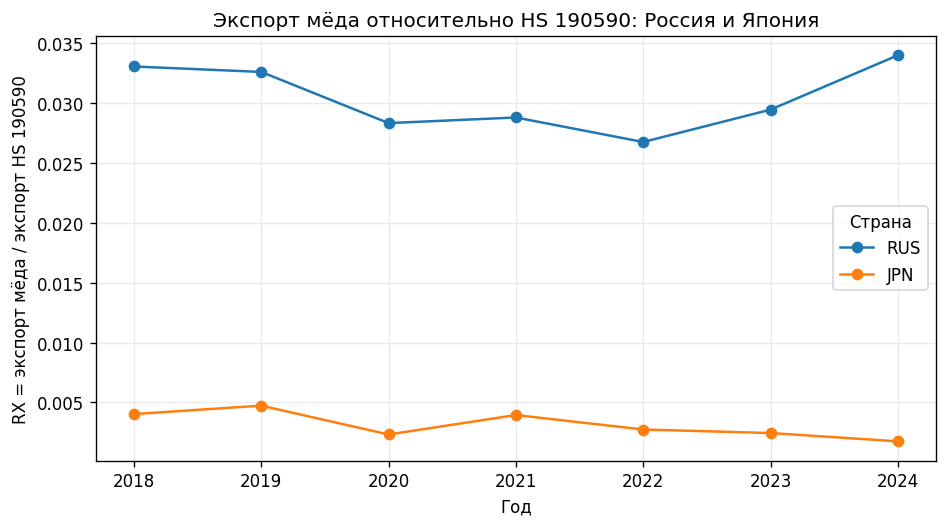

Лет с RX_RUS > RX_JPN: 7 из 7


In [6]:
rx_years = exports.pivot(index="Year", columns="ISO3", values="RX")[COMPARISON_ISO].sort_index()
assert rx_years.notna().all().all()
years_rus_higher = int((rx_years["RUS"] > rx_years[COMPARISON_ISO[1]]).sum())
display(rx_years)
ax = rx_years.plot(marker="o", figsize=(8, 4.5))
ax.set(title="Экспорт мёда относительно HS 190590: Россия и Япония",
       xlabel="Год", ylabel="RX = экспорт мёда / экспорт HS 190590")
ax.set_xticks(rx_years.index)
ax.grid(alpha=0.25)
ax.legend(title="Страна")
plt.tight_layout()
plt.show()
print(f"Лет с RX_RUS > RX_JPN: {years_rus_higher} из {len(rx_years)}")


## **[Синий, 2 балла, Красный, 2 балла]** Техническое задание 2. Факторная обеспеченность и чистый экспорт

### **[Синий, 1 балл]** Пункт 2а. Нормированный чистый экспорт

Используй `trade_p` и `factor_latest`, полученные в задании 1. Выбери последний год торговли и самостоятельно рассчитай для каждой страны

$$
NEX_i=\frac{X_i-M_i}{X_i+M_i}.
$$

Присоедини последний факторный показатель по ISO3 методом `merge()` и оставь страны из `SAMPLE_ISO`. Проверь, что все значения $NEX$ лежат между $-1$ и $1$. Источник и код факторного показателя уже сохранены в переменных первой ячейки.

**Исследовательский смысл.** $NEX$ сопоставляет экспорт и импорт товара с учётом общего масштаба торговли. Положительное значение указывает на преобладание экспорта, а отрицательное — импорта. Показатель не равен объёму выпуска и не измеряет внутреннее потребление.

**Что получить на выходе.** таблицу по странам с экспортом, импортом, $NEX$, факторным показателем и годами наблюдений.

**Пример вывода.**

| ISO3 | $X$ | $M$ | $NEX$ | фактор | год фактора |
|---|---:|---:|---:|---:|---:|
| [страна] | [экспорт] | [импорт] | [значение] | [значение] | [год] |

In [7]:
trade_year = int(trade_p["Year"].max())
latest_trade = trade_p.loc[trade_p["Year"].eq(trade_year)].copy()
assert latest_trade[["X", "M"]].ge(0).all().all()
assert latest_trade["X"].add(latest_trade["M"]).gt(0).all()
latest_trade["NEX"] = (latest_trade["X"] - latest_trade["M"]) / (latest_trade["X"] + latest_trade["M"])
sample = (latest_trade.loc[latest_trade["ISO3"].isin(SAMPLE_ISO)]
          .merge(factor_latest[["ISO3", "Фактор", "Год фактора"]], on="ISO3", validate="one_to_one"))
assert len(sample) == len(SAMPLE_ISO) >= 10
assert sample[["X", "M", "NEX", "Фактор", "Год фактора"]].notna().all().all()
assert sample["NEX"].between(-1, 1).all()
sample["Разрыв лет"] = sample["Year"] - sample["Год фактора"]
assert sample["Разрыв лет"].abs().le(1).all()
display(sample[["ISO3", "Страна", "Year", "X", "M", "NEX", "Фактор", "Год фактора", "Разрыв лет"]])
print(f"Стран: {len(sample)}. Год торговли: {trade_year}. X и M: долл. США.")
print("Все NEX в [-1; 1]; пропусков нет. Разрыв лет:", sorted(sample["Разрыв лет"].unique()))


,ISO3,Страна,Year,X,M,NEX,Фактор,Год фактора,Разрыв лет
0,ARG,Argentina,2024,"190,369,311.000000","1,813.000000",0.999981,1.025074,2024,0
1,AUS,Australia,2024,"45,365,702.000000","33,207,927.000000",0.154731,1.149690,2024,0
2,BRA,Brazil,2024,"101,111,986.000000","84,461.000000",0.998331,0.262464,2024,0
3,CAN,Canada,2024,"44,487,916.000000","47,044,342.000000",-0.027929,0.922488,2024,0
4,CHN,China,2024,"239,008,353.000000","47,079,414.000000",0.670874,0.076982,2024,0
5,DEU,Germany,2024,"132,801,451.000000","248,965,263.000000",-0.304280,0.139565,2024,0
6,FRA,France,2024,"27,889,207.000000","114,612,838.000000",-0.608578,0.246267,2024,0
7,GBR,United Kingdom,2024,"13,269,943.000000","120,065,674.000000",-0.800954,0.088400,2024,0
8,IRL,Ireland,2024,"4,211,067.000000","24,809,145.000000",-0.709784,0.080248,2024,0
9,JPN,Japan,2024,"578,331.000000","132,237,719.000000",-0.991291,0.032450,2024,0


Стран: 16. Год торговли: 2024. X и M: долл. США.
Все NEX в [-1; 1]; пропусков нет. Разрыв лет: [np.int64(0)]


### **[Синий, 1 балл]** Пункт 2б. Диаграмма факторной обеспеченности и торговли

Отсортируй `sample` по факторному показателю. Построй диаграмму рассеяния. По оси $x$ отложи факторный показатель, по оси $y$ — $NEX$. Подпиши страны и проведи горизонтальную линию $NEX=0$. Для графика можно использовать `plot.scatter()`, `annotate()` и `axhline()`.

**Исследовательский смысл.** Диаграмма показывает, согласуется ли знак чистого экспорта с простым факторным ожиданием в выбранной группе стран. Точки отражают страны, а не совместное предложение товаров и не равновесие спроса и предложения.

**Что получить на выходе.** отсортированную таблицу и читаемый подписанный график. В письменной части опиши общий рисунок и выбери две страны, которые в него не вписываются.

**Пример вывода.**

| ISO3 | фактор | $NEX$ | положение относительно ожидания |
|---|---:|---:|---|
| [страна] | [значение] | [значение] | согласуется / не согласуется |

Граница высокой и низкой обеспеченности - медиана: 0.130689 га/чел.


,ISO3,Страна,Фактор,NEX,Группа,Положение относительно ожидания
0,KOR,South Korea,0.025159,-0.976061,низкий фактор,согласуется
1,JPN,Japan,0.032450,-0.991291,низкий фактор,согласуется
2,NLD,Netherlands,0.055742,-0.561867,низкий фактор,согласуется
3,CHN,China,0.076982,0.670874,низкий фактор,не согласуется
4,IRL,Ireland,0.080248,-0.709784,низкий фактор,согласуется
5,GBR,United Kingdom,0.088400,-0.800954,низкий фактор,согласуется
6,NZL,New Zealand,0.098677,0.998796,низкий фактор,не согласуется
7,SAU,Saudi Arabia,0.121812,-0.568545,низкий фактор,согласуется
8,DEU,Germany,0.139565,-0.304280,высокий фактор,не согласуется
9,FRA,France,0.246267,-0.608578,высокий фактор,не согласуется


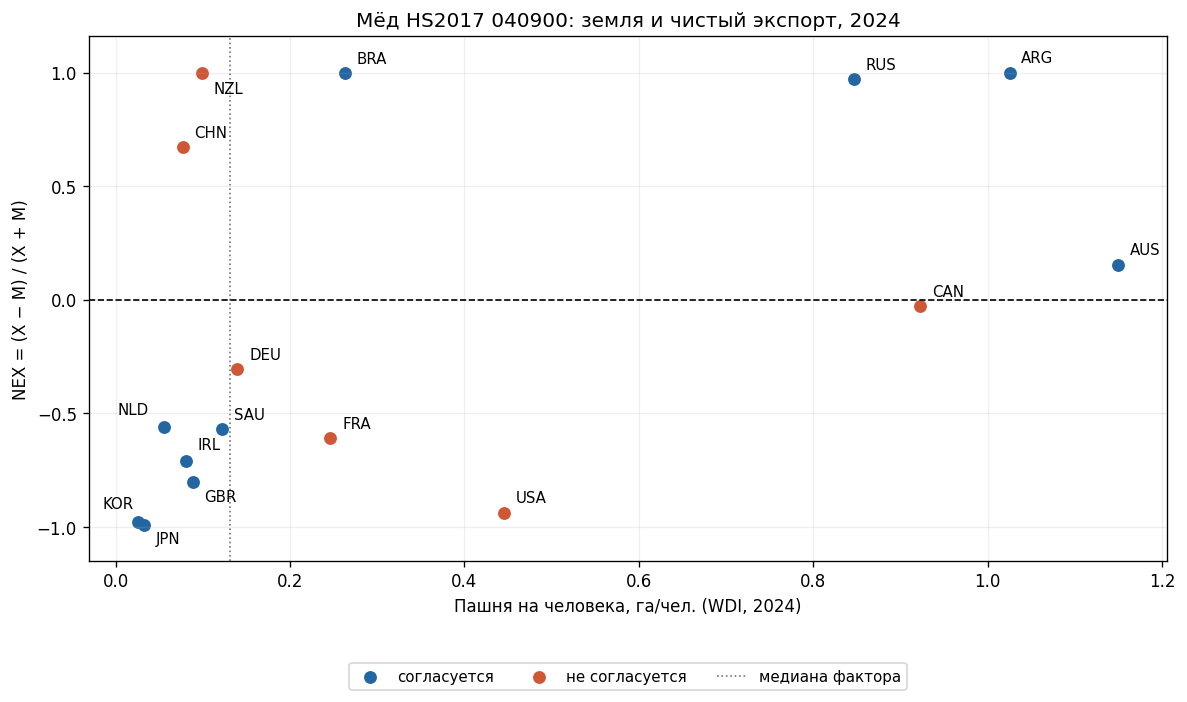

Вписываются в ожидание: KOR, JPN, NLD, IRL, GBR, SAU, BRA, RUS, ARG, AUS
Не вписываются: CHN, NZL, DEU, FRA, USA, CAN
Общий рисунок: есть и согласующиеся страны, и исключения; одной земли недостаточно для объяснения торговли мёдом.
Два примера, которые не вписываются:
USA (United States): 0.445740 га/чел., высокий фактор, NEX = -0.937224.
NZL (New Zealand): 0.098677 га/чел., низкий фактор, NEX = 0.998796.
У США показатель земли выше медианы, но преобладает импорт; у Новой Зеландии ниже медианы, но преобладает экспорт


In [19]:
sample = sample.sort_values("Фактор").reset_index(drop=True)
factor_median = sample["Фактор"].median()
sample["Группа"] = np.where(sample["Фактор"] >= factor_median, "высокий фактор", "низкий фактор")
outside = (((sample["Фактор"] >= factor_median) & (sample["NEX"] < 0)) |
           ((sample["Фактор"] < factor_median) & (sample["NEX"] > 0)))
sample["Положение относительно ожидания"] = np.where(outside, "не согласуется", "согласуется")
sample.loc[sample["NEX"].eq(0), "Положение относительно ожидания"] = "нулевой NEX"
print(f"Граница высокой и низкой обеспеченности - медиана: {factor_median:.6f} га/чел.")

display(sample[["ISO3", "Страна", "Фактор", "NEX", "Группа", "Положение относительно ожидания"]])
fig, ax = plt.subplots(figsize=(10, 6))
for label, color in [("согласуется", "#2466a2"), ("не согласуется", "#cf5736"), ("нулевой NEX", "#777777")]:
    part = sample.loc[sample["Положение относительно ожидания"].eq(label)]
    if not part.empty:
        ax.scatter(part["Фактор"], part["NEX"], label=label, color=color, s=45)
ax.axvline(factor_median, color="#777777", linestyle=":", linewidth=1, label="медиана фактора")
ax.axhline(0, color="black", linestyle="--", linewidth=1)
for _, row in sample.iterrows():
    # Разные отступы помогают прочитать близкие точки.
    offset = {"JPN": (7, -11), "KOR": (-21, 8), "NLD": (-28, 8),
              "IRL": (7, 7), "GBR": (7, -12), "SAU": (7, 6),
              "NZL": (7, -12), "CHN": (7, 6)}.get(row["ISO3"], (7, 6))
    ax.annotate(row["ISO3"], (row["Фактор"], row["NEX"]),
                xytext=offset, textcoords="offset points", fontsize=9)
ax.set(title=f"Мёд HS2017 040900: земля и чистый экспорт, {trade_year}",
       xlabel="Пашня на человека, га/чел. (WDI, 2024)", ylabel="NEX = (X − M) / (X + M)",
       ylim=(-1.15, 1.16))
ax.grid(alpha=0.2)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=9)
plt.tight_layout()
plt.show()


print("Вписываются в ожидание:", ", ".join(sample.loc[sample["Положение относительно ожидания"].eq("согласуется"), "ISO3"]))
print("Не вписываются:", ", ".join(sample.loc[outside, "ISO3"]))
print("Общий рисунок: есть и согласующиеся страны, и исключения; одной земли недостаточно для объяснения торговли мёдом.")
print("Два примера, которые не вписываются:")
for iso in ["USA", "NZL"]:
    row = sample.set_index("ISO3").loc[iso]
    print(f"{iso} ({row['Страна']}): {row['Фактор']:.6f} га/чел., {row['Группа']}, NEX = {row['NEX']:.6f}.")
print("У США показатель земли выше медианы, но преобладает импорт; у Новой Зеландии ниже медианы, но преобладает экспорт")



### **[Красный, 1 балл]** Пункт 2в. Результат для выборки в целом

Найди медиану факторного показателя и раздели страны на две группы: с высоким и низким значением фактора. Для каждой группы самостоятельно рассчитай

$$
s_g=\frac{\text{число стран с }NEX>0}{\text{число стран в группе }g}.
$$

Выведи таблицу групп, медиану и список исключений. Исключением считай страну с высоким факторным показателем и отрицательным $NEX$ либо с низким факторным показателем и положительным $NEX$. Для группировки можно использовать `median()`, `np.where()` и `groupby().agg()`.

**Исследовательский смысл.** Доли $s_g$ проверяют, чаще ли страны с большей обеспеченностью фактором являются чистыми экспортёрами товара. Деление по медиане удобно для учебного расчёта, но зависит от состава небольшой выборки.

**Что получить на выходе.** медиану показателя, таблицу двух групп с долями чистых экспортёров и список исключений.

**Пример вывода.**

| группа | стран | доля чистых экспортёров |
|---|---:|---:|
| высокий фактор | [число] | [доля] |
| низкий фактор | [число] | [доля] |

| ISO3 | фактор | $NEX$ | тип исключения |
|---|---:|---:|---|
| [страна] | [значение] | [значение] | высокий фактор / низкий фактор |

In [9]:
factor_median = sample["Фактор"].median()
# Равенство медиане относим к высокой группе; NEX=0 не считается исключением.
sample["Группа"] = np.where(sample["Фактор"] >= factor_median, "высокий фактор", "низкий фактор")
sample["Чистый экспортёр"] = sample["NEX"] > 0
groups = sample.groupby("Группа").agg(
    Стран=("ISO3", "size"), Чистых_экспортёров=("Чистый экспортёр", "sum"))
groups["Доля чистых экспортёров"] = groups["Чистых_экспортёров"] / groups["Стран"]
exception_mask = (((sample["Фактор"] >= factor_median) & (sample["NEX"] < 0)) |
                  ((sample["Фактор"] < factor_median) & (sample["NEX"] > 0)))
exceptions = sample.loc[exception_mask].copy()
exceptions["Тип исключения"] = np.where(exceptions["Фактор"] >= factor_median,
    "высокий фактор, чистый импорт", "низкий фактор, чистый экспорт")
sample["Положение относительно ожидания"] = np.where(exception_mask, "не согласуется", "согласуется")
sample.loc[sample["NEX"].eq(0), "Положение относительно ожидания"] = "нулевой NEX"
print(f"Медиана фактора: {factor_median:.6f} га/чел.")
display(groups)
display(sample[["ISO3", "Фактор", "NEX", "Группа", "Положение относительно ожидания"]])
display(exceptions[["ISO3", "Фактор", "NEX", "Тип исключения"]])
assert groups["Стран"].sum() == len(sample)
assert groups["Доля чистых экспортёров"].between(0, 1).all()


Медиана фактора: 0.130689 га/чел.


,Стран,Чистых_экспортёров,Доля чистых экспортёров
Группа,,,
высокий фактор,8,4,0.500000
низкий фактор,8,2,0.250000


,ISO3,Фактор,NEX,Группа,Положение относительно ожидания
0,KOR,0.025159,-0.976061,низкий фактор,согласуется
1,JPN,0.032450,-0.991291,низкий фактор,согласуется
2,NLD,0.055742,-0.561867,низкий фактор,согласуется
3,CHN,0.076982,0.670874,низкий фактор,не согласуется
4,IRL,0.080248,-0.709784,низкий фактор,согласуется
5,GBR,0.088400,-0.800954,низкий фактор,согласуется
6,NZL,0.098677,0.998796,низкий фактор,не согласуется
7,SAU,0.121812,-0.568545,низкий фактор,согласуется
8,DEU,0.139565,-0.304280,высокий фактор,не согласуется
9,FRA,0.246267,-0.608578,высокий фактор,не согласуется


,ISO3,Фактор,NEX,Тип исключения
3,CHN,0.076982,0.670874,"низкий фактор, чистый экспорт"
6,NZL,0.098677,0.998796,"низкий фактор, чистый экспорт"
8,DEU,0.139565,-0.304280,"высокий фактор, чистый импорт"
9,FRA,0.246267,-0.608578,"высокий фактор, чистый импорт"
11,USA,0.445740,-0.937224,"высокий фактор, чистый импорт"
13,CAN,0.922488,-0.027929,"высокий фактор, чистый импорт"


### **[Красный, 1 балл]** Пункт 2г. Исключения при заметном торговом обороте

Крайнее значение $NEX$ может возникнуть при очень маленьких потоках. Рассчитай торговый оборот товара $T_i=X_i+M_i$. Оставь страны с оборотом не ниже медианы и снова найди исключения из факторного ожидания. Сравни полученный список с `exceptions` из пункта 2в.

**Исследовательский смысл.** Фильтр по обороту отделяет заметные торговые связи от крайних отношений, полученных на малых значениях. Сохранившееся исключение требует содержательного объяснения, но ещё не является парадоксом Леонтьева: для такого вывода нужно оценить факторное содержание экспорта и импорта.

**Что получить на выходе.** медиану оборота и таблицу исключений, которые сохраняются среди стран с заметной торговлей.

**Пример вывода.**

```text
Медиана торгового оборота: [значение]
```

| ISO3 | оборот | фактор | $NEX$ |
|---|---:|---:|---:|
| [страна] | [значение] | [значение] | [значение] |

In [10]:
sample["Оборот"] = sample["X"] + sample["M"]
turnover_median = sample["Оборот"].median()
# Медиана фактора и определение исключения остаются прежними.
large_exceptions = sample.loc[sample["Оборот"].ge(turnover_median) & exception_mask].copy()
print(f"Медиана торгового оборота: {turnover_median:,.2f} долл. США")
display(large_exceptions[["ISO3", "Оборот", "Фактор", "NEX", "Группа"]])
print("Исключения до фильтра:", ", ".join(sorted(exceptions["ISO3"])))
print("Сохранились:", ", ".join(sorted(large_exceptions["ISO3"])))
print("Отсеяны из-за оборота ниже медианы:",
      ", ".join(sorted(set(exceptions["ISO3"]) - set(large_exceptions["ISO3"]))) )
assert set(large_exceptions["ISO3"]).issubset(set(exceptions["ISO3"]))


Медиана торгового оборота: 117,006,248.50 долл. США


,ISO3,Оборот,Фактор,NEX,Группа
3,CHN,"286,087,767.000000",0.076982,0.670874,низкий фактор
6,NZL,"251,461,006.000000",0.098677,0.998796,низкий фактор
8,DEU,"381,766,714.000000",0.139565,-0.304280,высокий фактор
9,FRA,"142,502,045.000000",0.246267,-0.608578,высокий фактор
11,USA,"641,370,721.000000",0.445740,-0.937224,высокий фактор


Исключения до фильтра: CAN, CHN, DEU, FRA, NZL, USA
Сохранились: CHN, DEU, FRA, NZL, USA
Отсеяны из-за оборота ниже медианы: CAN


## **[Чёрный, 3 балла + 1 бонусный балл]** Техническое задание 3. Сопоставление импортных рынков и итог для PDF-отчёта

### **[Чёрный, 1 балл]** Пункт 3а. Сопоставление импортных рынков

Выбери шесть стран и запиши их в `MARKET_ISO`. Включи не менее двух крупных импортёров, двух стран с заметным ростом импорта и две страны с различной факторной обеспеченностью или разным знаком $NEX$. Категории могут пересекаться. Используй 2021 год и последний год панели:

$$
g_i=\left(\frac{M_{i,t_1}}{M_{i,t_0}}-1\right)\cdot100\%.
$$

Сам выбери строки двух лет, переименуй столбцы методом `rename()`, соедини таблицы через `merge()` и рассчитай $g_i$. Переведи импорт в миллиарды долларов.

**Исследовательский смысл.** Масштаб импорта, его изменение, $NEX$ и факторная обеспеченность отвечают на разные вопросы. Их нужно сопоставлять, а не складывать в готовый рейтинг перспективности.

**Пример вывода.**

| ISO3 | импорт 2021 | импорт последнего года | изменение, % | $NEX$ | фактор |
|---|---:|---:|---:|---:|---:|
| [страна] | [млрд долл.] | [млрд долл.] | [темп] | [значение] | [значение] |

In [11]:
base_year = 2021
imports_base = (trade_p.loc[trade_p["Year"].eq(base_year) & trade_p["ISO3"].isin(MARKET_ISO), ["ISO3", "M"]]
                .rename(columns={"M": "M_2021_USD"}))
imports_last = (trade_p.loc[trade_p["Year"].eq(trade_year) & trade_p["ISO3"].isin(MARKET_ISO), ["ISO3", "M"]]
                .rename(columns={"M": "M_last_USD"}))
markets = imports_base.merge(imports_last, on="ISO3", validate="one_to_one")
assert markets["M_2021_USD"].gt(0).all()
markets["Изменение, %"] = (markets["M_last_USD"] / markets["M_2021_USD"] - 1) * 100
markets["Импорт 2021, млрд долл."] = markets["M_2021_USD"] / 1e9
markets["Импорт 2024, млрд долл."] = markets["M_last_USD"] / 1e9
markets = markets.merge(sample[["ISO3", "Страна", "NEX", "Фактор", "Год фактора"]],
                        on="ISO3", validate="one_to_one")
markets["Год торговли"] = trade_year
markets = markets.set_index("ISO3").loc[MARKET_ISO].reset_index()
assert len(markets) == 6 and markets.notna().all().all()
market_columns = ["ISO3", "Импорт 2021, млрд долл.", "Импорт 2024, млрд долл.",
                  "Изменение, %", "NEX", "Фактор", "Год фактора", "Год торговли"]
display(markets[market_columns])

world_imports = latest_trade.sort_values("M", ascending=False).copy()
world_imports["Место по импорту в базе"] = world_imports["M"].rank(ascending=False, method="min").astype(int)
display(world_imports.loc[world_imports["ISO3"].isin(["USA", "DEU"]),
                         ["ISO3", "M", "Место по импорту в базе"]])
growing_markets = markets.loc[markets["ISO3"].isin(["NLD", "IRL"]), ["ISO3", "Изменение, %"]]
assert len(growing_markets) == 2 and growing_markets["Изменение, %"].gt(0).all()
display(growing_markets)
print("USA и DEU — два крупнейших импортёра базы; NLD и IRL — рынки с ростом стоимости импорта.")
print("JPN и KOR сохраняют пару из ДЗ-1. Обеспеченность землёй у шести стран различается.")
print("Рост — изменение стоимости в текущих долларах, а не физического объёма.")


,ISO3,"Импорт 2021, млрд долл.","Импорт 2024, млрд долл.","Изменение, %",NEX,Фактор,Год фактора,Год торговли
0,USA,0.626533,0.621239,-0.844842,-0.937224,0.445740,2024,2024
1,DEU,0.337941,0.248965,-26.328754,-0.304280,0.139565,2024,2024
2,NLD,0.067406,0.074510,10.539382,-0.561867,0.055742,2024,2024
3,IRL,0.017688,0.024809,40.263313,-0.709784,0.080248,2024,2024
4,JPN,0.168619,0.132238,-21.576202,-0.991291,0.032450,2024,2024
5,KOR,0.015037,0.016457,9.440330,-0.976061,0.025159,2024,2024


,ISO3,M,Место по импорту в базе
1496,USA,"621,239,436.000000",1
1342,DEU,"248,965,263.000000",2


,ISO3,"Изменение, %"
2,NLD,10.539382
3,IRL,40.263313


USA и DEU — два крупнейших импортёра базы; NLD и IRL — рынки с ростом стоимости импорта.
JPN и KOR сохраняют пару из ДЗ-1. Обеспеченность землёй у шести стран различается.
Рост — изменение стоимости в текущих долларах, а не физического объёма.


### **[Чёрный, 1 балл]** Пункт 3б. Места стран по трём показателям

Для каждой страны из `markets` рассчитай три места. Первое определяется импортом последнего года, второе — темпом его изменения, третье — импортной зависимостью. Для последнего показателя более отрицательный $NEX$ означает более высокое место. Используй метод `.rank()`.

**Исследовательский смысл.** Три места не нужно объединять в единственный балл. Большой рынок, быстро растущий рынок и импортозависимый рынок могут быть разными странами и требуют разных объяснений.

**Пример вывода.**

| ISO3 | место по импорту | место по росту | место по импортной зависимости |
|---|---:|---:|---:|
| [страна] | [место] | [место] | [место] |

In [12]:
# При равенстве значений страны получают одинаковое лучшее место (method='min').
markets["Место по импорту"] = markets["M_last_USD"].rank(ascending=False, method="min").astype(int)
markets["Место по росту"] = markets["Изменение, %"].rank(ascending=False, method="min").astype(int)
markets["Место по импортной зависимости"] = markets["NEX"].rank(ascending=True, method="min").astype(int)
display(markets[["ISO3", "Место по импорту", "Место по росту", "Место по импортной зависимости"]])
print("Места рассчитаны только среди шести выбранных рынков. Места не складываются.")
print("Импортная зависимость здесь — условное название ранга по NEX; это не доля импорта в потреблении.")


,ISO3,Место по импорту,Место по росту,Место по импортной зависимости
0,USA,1,4,3
1,DEU,2,6,6
2,NLD,4,2,5
3,IRL,5,1,4
4,JPN,3,5,1
5,KOR,6,3,2


Места рассчитаны только среди шести выбранных рынков. Места не складываются.
Импортная зависимость здесь — условное название ранга по NEX; это не доля импорта в потреблении.


### **[Чёрный, 1 балл]** Пункт 3в. Прямое сопоставление двух стран

Выбери две страны из `markets` и запиши их коды в `CASE_ISO`. Выведи их строки и рассчитай разницу в импорте последнего года, темпе изменения импорта и $NEX$. Первой считай первую страну в `CASE_ISO`.

**Исследовательский смысл.** Парное сопоставление помогает сформулировать проверяемые гипотезы о различиях между рынками. Оно не должно превращаться в окончательный выбор страны без данных о барьерах, логистике, конкуренции и внутреннем спросе.

**Что получить на выходе.** две строки исходной таблицы и три разности, рассчитанные как «первая страна минус вторая». Эти значения должны без повторных расчётов переноситься в письменную часть.

**Пример вывода.**

| показатель | первая страна | вторая страна | разность |
|---|---:|---:|---:|
| импорт последнего года | [значение] | [значение] | [разность] |
| изменение импорта, % | [значение] | [значение] | [разность] |
| $NEX$ | [значение] | [значение] | [разность] |

In [13]:
case = markets.set_index("ISO3").loc[CASE_ISO].copy()
display(case[market_columns[1:]])
case_metrics = ["Импорт 2024, млрд долл.", "Изменение, %", "NEX"]
case_difference = pd.DataFrame({
    "Показатель": case_metrics,
    CASE_ISO[0]: case.loc[CASE_ISO[0], case_metrics].astype(float).values,
    CASE_ISO[1]: case.loc[CASE_ISO[1], case_metrics].astype(float).values})
case_difference["Первая минус вторая"] = case_difference[CASE_ISO[0]] - case_difference[CASE_ISO[1]]
case_difference["Единицы разности"] = ["млрд долл. США", "процентные пункты", "безразмерная величина"]
display(case_difference)
print("Порядок вычитания: KOR − JPN. Изменение импорта рассчитано за 2021–2024 годы.")


,"Импорт 2021, млрд долл.","Импорт 2024, млрд долл.","Изменение, %",NEX,Фактор,Год фактора,Год торговли
ISO3,,,,,,,
KOR,0.015037,0.016457,9.440330,-0.976061,0.025159,2024,2024
JPN,0.168619,0.132238,-21.576202,-0.991291,0.032450,2024,2024


,Показатель,KOR,JPN,Первая минус вторая,Единицы разности
0,"Импорт 2024, млрд долл.",0.016457,0.132238,-0.115781,млрд долл. США
1,"Изменение, %",9.440330,-21.576202,31.016532,процентные пункты
2,NEX,-0.976061,-0.991291,0.015230,безразмерная величина


Порядок вычитания: KOR − JPN. Изменение импорта рассчитано за 2021–2024 годы.


### **[Чёрный, 1 бонусный балл]** Пункт 3г. Публикации к выводам

Выбери один или несколько содержательных выводов из блокнота, которые твоя команда переносит в PDF-отчёт. Для каждого вывода найди одну или несколько надёжных публикаций, которые подтверждают определение показателя, единицы измерения, данные или важное ограничение вывода. Подойдут официальная статистика, методическое описание базы, документ международной организации, отраслевой материал или рецензируемая статья.

Укажи организацию или авторов, название, год или дату публикации, прямую ссылку и дату обращения. Коротко запиши, какой именно вывод поддерживает публикация и чего она не доказывает. Одной пары «вывод — публикация» достаточно для полного бонусного балла. Если хочешь, добавь ещё. Литературный обзор делать не нужно.

**Что должно получиться.** Таблица `source_check` из одной или нескольких строк. Каждая строка связывает один вывод с одной публикацией.

| вывод из блокнота | источник | ссылка | что подтверждает | чего не доказывает |
|---|---|---|---|---|
| [конкретный вывод] | [организация, название, дата] | https://... | [точная связь] | [граница источника] |

In [14]:
source_check = pd.DataFrame([
    {
        "Вывод из блокнота": "Показатель фактора измерен в гектарах пашни на человека, а не общей площадью страны.",
        "Источник": "World Bank / FAO. WDI Metadata Glossary: AG.LND.ARBL.HA.PC; дата публикации страницы не указана",
        "Ссылка": "https://databank.worldbank.org/metadataglossary/world-development-indicators/series/AG.LND.ARBL.HA.PC",
        "Дата обращения": ACCESS_DATE,
        "Что подтверждает": "Определение пашни, единицы га/чел. и ограничения межстрановой сопоставимости.",
        "Чего не доказывает": "Не измеряет площадь медоносов, затраты земли на тонну мёда или причину знака NEX."
    },
    {
        "Вывод из блокнота": "Связь мёда с землёй требует осторожности: пашня не охватывает все пригодные для пчеловодства территории.",
        "Источник": "Nicola Bradbear / FAO. Beekeeping and sustainable livelihoods, FAO Diversification booklet 1, 2004",
        "Ссылка": "https://www.fao.org/4/y5110e/y5110e02.htm",
        "Дата обращения": ACCESS_DATE,
        "Что подтверждает": "Пчеловодство использует цветущие растения и природные условия как на обрабатываемых, так и на диких территориях.",
        "Чего не доказывает": "Не устанавливает, что мёд землеёмче HS 190590, и не объясняет каждое исключение в выборке."
    },
    {
        "Вывод из блокнота": f"В таблицах торговли используются доллары США и одна версия HS2017; последний год — {trade_year}.",
        "Источник": "OEC / CEPII BACI. Метаданные trade_i_baci_a_17, HS6 REV. 2017 (2018–2024); дата публикации не указана",
        "Ссылка": "https://api.oec.world/tesseract/cubes/trade_i_baci_a_17",
        "Дата обращения": ACCESS_DATE,
        "Что подтверждает": "Версию классификации, период базы и USD как единицы Trade Value. Числа получены по прямым запросам из журнала источников.",
        "Чего не доказывает": "Рост стоимости не доказывает рост количества, а большой импорт — готовую перспективность рынка."
    }
])
display(source_check)


,Вывод из блокнота,Источник,Ссылка,Дата обращения,Что подтверждает,Чего не доказывает
0,"Показатель фактора измерен в гектарах пашни на человека, а не общей площадью страны.",World Bank / FAO. WDI Metadata Glossary: AG.LND.ARBL.HA.PC; дата публикации страницы не указана,https://databank.worldbank.org/metadataglossary/world-development-indicators/series/AG.LND.ARBL.HA.PC,19.10.2026,"Определение пашни, единицы га/чел. и ограничения межстрановой сопоставимости.","Не измеряет площадь медоносов, затраты земли на тонну мёда или причину знака NEX."
1,Связь мёда с землёй требует осторожности: пашня не охватывает все пригодные для пчеловодства территории.,"Nicola Bradbear / FAO. Beekeeping and sustainable livelihoods, FAO Diversification booklet 1, 2004",https://www.fao.org/4/y5110e/y5110e02.htm,19.10.2026,"Пчеловодство использует цветущие растения и природные условия как на обрабатываемых, так и на диких территориях.","Не устанавливает, что мёд землеёмче HS 190590, и не объясняет каждое исключение в выборке."
2,В таблицах торговли используются доллары США и одна версия HS2017; последний год — 2024.,"OEC / CEPII BACI. Метаданные trade_i_baci_a_17, HS6 REV. 2017 (2018–2024); дата публикации не указана",https://api.oec.world/tesseract/cubes/trade_i_baci_a_17,19.10.2026,"Версию классификации, период базы и USD как единицы Trade Value. Числа получены по прямым запросам из журнала источников.","Рост стоимости не доказывает рост количества, а большой импорт — готовую перспективность рынка."
